In [6]:
import numpy as np
import pandas as pd
from IPython.display import display
from pathlib import Path
import matplotlib.pyplot as plt
import re

from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

import spacy

In [7]:
data_path = Path("../data/processed")

csv_files = list(data_path.glob("*.csv"))

display(csv_files[0].name)

def read_datasets(datasets):
    dataframe = {}
    for dataset in datasets:
        filename = dataset.name
        dataframe[filename] = pd.read_csv(dataset)
    return dataframe

def convert_to_datetime(dataset, columns):
    for column in columns:
        dataset[column] = pd.to_datetime(dataset[column])
    return dataset

orders_dataset_columns_to_datetime = [
    "order_purchase_timestamp", 
    "order_approved_at", 
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date" 
    ]

order_items_dataset_columns_to_datetime = [
    "shipping_limit_date" 
    ]

order_reviews_dataset_columns_to_datetime = [
    "review_creation_date",
    "review_answer_timestamp" 
    ]

datasets = read_datasets(csv_files)

customers_dataset = datasets["olist_customers_dataset.csv"]
geolocation_dataset = datasets["olist_geolocation_dataset.csv"]
order_payments_dataset = datasets["olist_order_payments_dataset.csv"]
products_dataset = datasets["olist_products_dataset.csv"]
sellers_dataset = datasets["olist_sellers_dataset.csv"]
category_translation_dataset = datasets["product_category_name_translation.csv"]

orders_dataset = convert_to_datetime(dataset=datasets["olist_orders_dataset.csv"], columns=orders_dataset_columns_to_datetime)
orders_items_dataset = convert_to_datetime(dataset=datasets["olist_order_items_dataset.csv"], columns=order_items_dataset_columns_to_datetime)
reviews_dataset = convert_to_datetime(dataset=datasets["olist_order_reviews_dataset.csv"], columns=order_reviews_dataset_columns_to_datetime)

display(orders_dataset.dtypes)
display(orders_items_dataset.dtypes)
display(reviews_dataset.dtypes)

'olist_customers_dataset.csv'

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

review_id                             str
order_id                              str
review_score                        int64
review_comment_title                  str
review_comment_message                str
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object

In [8]:
one_point_reviews = reviews_dataset[reviews_dataset["review_score"] == 1]
one_point_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,NaN,NaN,2018-04-13,2018-04-16 00:39:37
19,373cbeecea8286a2b66c97b1b157ec46,583174fbe37d3d5f0d6661be3aad1786,1,Não chegou meu produto,Péssimo,2018-08-15,2018-08-15 04:10:37
29,2c5e27fc178bde7ac173c9c62c31b070,0ce9a24111d850192a933fcaab6fbad3,1,NaN,Não gostei ! Comprei gato por lebre,2017-12-13,2017-12-16 07:14:07
32,58044bca115705a48fe0e00a21390c54,68e55ca79d04a79f20d4bfc0146f4b66,1,NaN,Sempre compro pela Internet e a entrega ocorre...,2018-04-08,2018-04-09 12:22:39
39,9fd59cd04b42f600df9f25e54082a8d1,3c314f50bc654f3c4e317b055681dff9,1,NaN,Nada de chegar o meu pedido.,2017-04-21,2017-04-23 05:37:03


In [ ]:
one_point_reviews = one_point_reviews[one_point_reviews["review_comment_message"].notna()]
one_point_reviews

review_id                  8745
order_id                   8745
review_score               8745
review_comment_title       1789
review_comment_message     8745
review_creation_date       8745
review_answer_timestamp    8745
dtype: int64

In [11]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-záàâãéêíóôõúç\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()

one_point_reviews["cleaned_text"] = one_point_reviews["review_comment_message"].apply(clean_text)


In [18]:
one_point_reviews.head(1)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,cleaned_text,processed_text
19,373cbeecea8286a2b66c97b1b157ec46,583174fbe37d3d5f0d6661be3aad1786,1,Não chegou meu produto,Péssimo,2018-08-15,2018-08-15 04:10:37,péssimo,péssimo


In [14]:
nlp = spacy.load(
    "pt_core_news_sm",
    disable=["ner", "parser"]
)

In [15]:
def preprocess(text):
    doc = nlp(text)

    words = []

    for token in doc:
        if token.is_alpha and not token.is_stop:
            words.append(token.lemma_)
    
    return " ".join(words)

one_point_reviews["processed_text"] = one_point_reviews["cleaned_text"].apply(preprocess)

In [17]:
one_point_reviews.head(5)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,cleaned_text,processed_text
19,373cbeecea8286a2b66c97b1b157ec46,583174fbe37d3d5f0d6661be3aad1786,1,Não chegou meu produto,Péssimo,2018-08-15,2018-08-15 04:10:37,péssimo,péssimo
29,2c5e27fc178bde7ac173c9c62c31b070,0ce9a24111d850192a933fcaab6fbad3,1,NaN,Não gostei ! Comprei gato por lebre,2017-12-13,2017-12-16 07:14:07,não gostei comprei gato por lebre,gostar comprei gato Lebre
32,58044bca115705a48fe0e00a21390c54,68e55ca79d04a79f20d4bfc0146f4b66,1,NaN,Sempre compro pela Internet e a entrega ocorre...,2018-04-08,2018-04-09 12:22:39,sempre compro pela internet e a entrega ocorre...,compro Internet entrega ocorrer prazo combinad...
39,9fd59cd04b42f600df9f25e54082a8d1,3c314f50bc654f3c4e317b055681dff9,1,NaN,Nada de chegar o meu pedido.,2017-04-21,2017-04-23 05:37:03,nada de chegar o meu pedido,chegar pedido
51,e233e51d11511bf30e568c76360ace52,548df2c6e5f089574614894bca78acf5,1,NaN,recebi somente 1 controle Midea Split ESTILO.\...,2018-01-28,2018-02-04 11:06:15,recebi somente controle midea split estilo fal...,recebi controle midea splitr estilo faltar con...


In [19]:
all_words = " ".join(one_point_reviews["processed_text"]).split()

In [20]:
all_words

['péssimo',
 'gostar',
 'comprei',
 'gato',
 'Lebre',
 'compro',
 'Internet',
 'entrega',
 'ocorrer',
 'prazo',
 'combinado',
 'acreditar',
 'prazo',
 'stark',
 'prazo',
 'esgotar',
 'recebi',
 'produto',
 'chegar',
 'pedido',
 'recebi',
 'controle',
 'midea',
 'splitr',
 'estilo',
 'faltar',
 'controle',
 'remoto',
 'ar',
 'condicionado',
 'consul',
 'produto',
 'chegar',
 'prazo',
 'estipular',
 'causar',
 'transtorno',
 'pq',
 'programei',
 'viagem',
 'férias',
 'filho',
 'basear',
 'prazo',
 'moro',
 'bahia',
 'cuiabá',
 'sozinho',
 'casa',
 'vazer',
 'produto',
 'inferior',
 'acabar',
 'pedir',
 'reembolso',
 'resposta',
 'pedido',
 'balde',
 'peça',
 'bloco',
 'montar',
 'un',
 'r',
 'entregar',
 'vender',
 'entregar',
 'targaryen',
 'tapete',
 'eva',
 'n',
 'letra',
 'peço',
 'crianço',
 'un',
 'r',
 'entreg',
 'comprei',
 'tr',
 'pacote',
 'folha',
 'papel',
 'transfer',
 'tecido',
 'escuro',
 'so',
 'recebi',
 'funcionar',
 'sincronismo',
 'chegar',
 'peça',
 'nota',
 'garanti

In [22]:
word_counts = Counter(all_words)

top_word_counts_pd = pd.DataFrame(
    word_counts.most_common(30),
    columns=["word", "count"]
)

display(top_word_counts_pd)

,word,count
0,produto,5484
1,recebi,2546
2,entregar,1815
3,comprei,1409
4,chegar,1261
5,vir,1154
6,dia,991
7,entrega,967
8,compra,819
9,nao,816


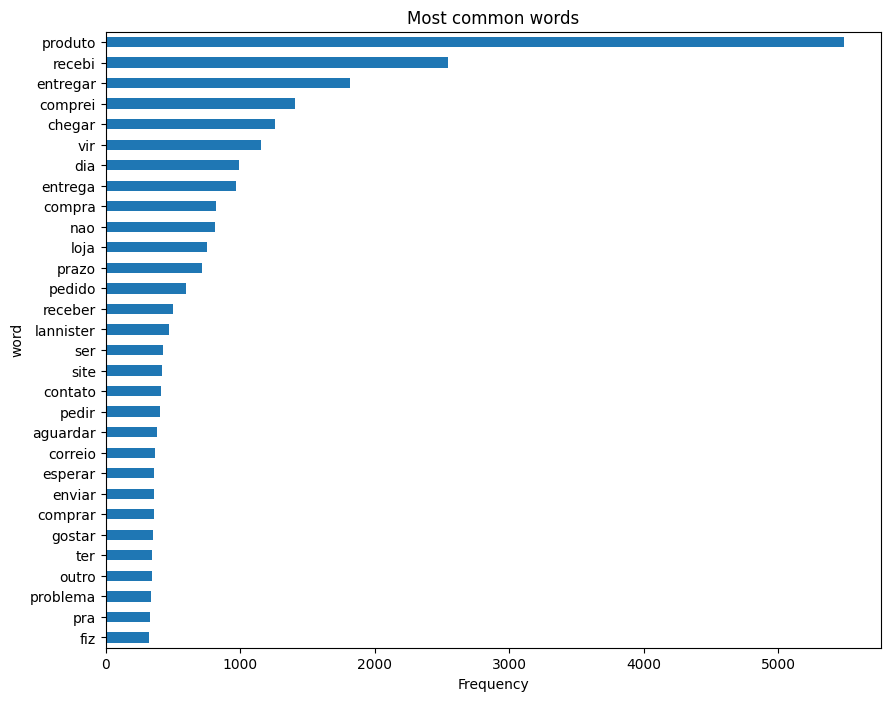

In [26]:
top_word_counts_pd.sort_values("count").plot.barh(
    x="word",
    y="count",
    legend=False,
    figsize=(10, 8)
)

plt.xlabel("Frequency")
plt.title("Most common words")
plt.show()